# November 2026 — Capstone: the Late-2026 Frontier Recipe

Notebook 58 assembled the early-2026 recipe (Qwen3.5 / DeepSeek-V4). Over the rest of 2026 almost every component was replaced by a refined version. This capstone assembles the **late-2026** recipe as published by the open labs, and trains it next to a GPT-2 baseline.

| component | late-2026 version | seen in | notebook |
|---|---|---|---|
| linear-memory layers (3 of every 4) | **Gated DeltaNet-2**: channel-wise decay, separate erase and write gates | NVIDIA GDN-2; KDA in Kimi K3/K3.1, Ling 3.1, Solar Open 2, GLM-5.3 | 59, 63 |
| global layers (1 of every 4) | **gated sparse attention** with a **block-compressed indexer** (top-k blocks + current block) | Qwen3.8 QSA, Kimi K3.1 Pro (DSA), DeepSeek-V4.1 CSA2 | 54, 65 |
| residual path | **Block Attention Residuals** (softmax over depth) | Kimi AttnRes; Qwen's Gated Residual and DeepSeek's mHC are the alternatives | 55, 61, 64 |
| feed-forward | **LatentMoE**: router on $d$, experts in $\ell=d/4$, 4× experts and 4× top-k, shared expert, bias-based balancing | Nemotron 3 Super/Ultra, Muse Spark Open | 44, 62 |
| extra objective | multi-token prediction (depth 1) | everyone | 47 |
| optimizer | Muon for matrices, AdamW for the rest | Kimi, DeepSeek-V4, Qwen3.8 | 53 |
| schedule | **constant LR + weight averaging** (EMA) | Kolibri-1 (WSD elsewhere) | 68 |

Not included: Mamba-3 (60, used in SSM hybrids), the causal encoder–decoder split (66), looping (67), Engram/N-gram memory (56), MLA, and post-training (38, 48).

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cpu | device: cpu


In [2]:
# A procedurally generated corpus (~290K characters) with a real held-out split.
_rng = random.Random(0)
_subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
_verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
_objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
_advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def _sentence():
    s = f"{_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)} {_rng.choice(_advs)}"
    if _rng.random() < 0.4: s += f" because {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    if _rng.random() < 0.2: s += f", then {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(_sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
print(f"{len(text):,} characters, vocab {V}")
CTX = 64

290,321 characters, vocab 31


## Components (compact versions of notebooks 61–65)

In [3]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

def rope(x, base=10000.0):
    T, d = x.shape[-2], x.shape[-1]
    inv = 1.0 / base ** (torch.arange(0, d, 2, device=x.device).float() / d)
    ang = torch.arange(T, device=x.device).float()[:, None] * inv
    x1, x2 = x[..., ::2], x[..., 1::2]
    return torch.stack([x1 * ang.cos() - x2 * ang.sin(), x1 * ang.sin() + x2 * ang.cos()], -1).flatten(-2)

def gdn2_chunked(q, k, v, log_alpha, b, w, C=16):
    """Gated DeltaNet-2, chunkwise (notebook 63)."""
    B, H, T, dk = k.shape; S = k.new_zeros(B, H, dk, v.shape[-1]); outs = []
    for s in range(0, T, C):
        qc, kc, vc, lc, bc, wc = (x[:, :, s:s + C] for x in (q, k, v, log_alpha, b, w))
        n = kc.shape[2]; ec, zc = bc * kc, wc * vc; G = torch.cumsum(lc, 2)
        causal = torch.ones(n, n, dtype=torch.bool, device=k.device).tril()
        E = torch.exp((G[:, :, :, None, :] - G[:, :, None, :, :]).masked_fill(~causal[None, None, :, :, None], float("-inf")))
        EK = torch.einsum("bhtc,bhic,bhtic->bhti", ec, kc, E); QK = torch.einsum("bhtc,bhic,bhtic->bhti", qc, kc, E); g = torch.exp(G)
        U = torch.linalg.solve_triangular(torch.eye(n, device=k.device) + torch.tril(EK, -1), zc - (g * ec) @ S, upper=False, unitriangular=True)
        outs.append((g * qc) @ S + QK @ U)
        S = torch.exp(G[:, :, -1, :, None]) * S + (torch.exp(G[:, :, -1:, :] - G) * kc).transpose(-1, -2) @ U
    return torch.cat(outs, 2)

class GDN2(nn.Module):
    def __init__(self, d, heads=2):
        super().__init__(); self.h, self.dk = heads, d // heads
        self.qkv = nn.Linear(d, 3 * d, bias=False); self.conv = nn.Conv1d(3 * d, 3 * d, 4, groups=3 * d, padding=3)
        self.w_b, self.w_w, self.w_f = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.a = nn.Parameter(torch.log(torch.empty(d).uniform_(1, 16)))
        with torch.no_grad(): self.w_f.bias.copy_(torch.log(torch.expm1(torch.empty(d).uniform_(1e-3, 0.1))))
        self.gate, self.onorm, self.o = nn.Linear(d, d, bias=False), RMSNorm(self.dk), nn.Linear(d, d, bias=False)
    def forward(self, x):
        B, T, D = x.shape; sh = lambda t: t.view(B, T, self.h, self.dk).transpose(1, 2)
        q, k, v = F.silu(self.conv(self.qkv(x).transpose(1, 2))[..., :T].transpose(1, 2)).chunk(3, -1)
        q, k, v = F.normalize(sh(q), dim=-1), F.normalize(sh(k), dim=-1), sh(v)
        log_alpha = sh(-torch.exp(self.a) * F.softplus(self.w_f(x)))
        o = gdn2_chunked(q, k, v, log_alpha, sh(torch.sigmoid(self.w_b(x))), sh(torch.sigmoid(self.w_w(x))))
        return self.o(F.silu(self.gate(x)) * self.onorm(o).transpose(1, 2).reshape(B, T, D))

class SparseGatedAttention(nn.Module):
    """Gated attention (RoPE, QK-norm, GQA) reading only the top-k blocks chosen by a QSA-style block indexer, plus the current block.
    The indexer learns by distilling block-max-pooled attention (KL); `sparse` switches selection on after a dense warm-up."""
    def __init__(self, d, heads=4, kv_heads=2, r=4, topk=16, di=16, hi=2):
        super().__init__(); self.h, self.kvh, self.dh, self.r, self.kb = heads, kv_heads, d // heads, r, topk // r
        self.wq, self.wkv = nn.Linear(d, d, bias=False), nn.Linear(d, 2 * kv_heads * self.dh, bias=False)
        self.qn, self.kn = RMSNorm(self.dh), RMSNorm(self.dh)
        self.gate, self.o = nn.Linear(d, d), nn.Linear(d, d, bias=False)
        self.iq, self.ik, self.hi, self.di = nn.Linear(d, hi * di, bias=False), nn.Linear(d, di, bias=False), hi, di
        self.sparse, self.kl = False, torch.tensor(0.0)
    def forward(self, x):
        B, T, D = x.shape; r = self.r; nb = T // r; Tb = nb * r                          # blocks cover the first Tb tokens
        q = self.wq(x).view(B, T, self.h, self.dh).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.kvh, self.dh).permute(2, 0, 3, 1, 4)
        q, k = rope(self.qn(q)), rope(self.kn(k))
        k, v = k.repeat_interleave(self.h // self.kvh, 1), v.repeat_interleave(self.h // self.kvh, 1)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dh)
        i = torch.arange(T, device=x.device); causal = i[None, :] <= i[:, None]
        complete = (torch.arange(nb, device=x.device)[None, :] * r + r - 1) <= i[:, None]
        iq = F.rms_norm(self.iq(x.detach()).view(B, T, self.hi, self.di), (self.di,))
        ik = F.rms_norm(self.ik(x[:, :Tb].detach()).view(B, nb, r, self.di).mean(2), (self.di,))
        idx = F.relu(torch.einsum("bthd,bnd->btn", iq, ik)).masked_fill(~complete, -1e9)
        with torch.no_grad():
            dense = scores.masked_fill(~causal, float("-inf")).softmax(-1).sum(1)[..., :Tb]
            teacher = dense.reshape(B, T, nb, r).amax(-1).masked_fill(~complete, 0)
            teacher = teacher / teacher.sum(-1, keepdim=True).clamp_min(1e-9)
        valid = complete.any(-1)
        logp = idx.log_softmax(-1).masked_fill(~complete, 0)
        self.kl = (teacher * (teacher.clamp_min(1e-9).log() - logp)).sum(-1)[:, valid].mean()
        allowed = causal.expand(B, T, T)
        if self.sparse:
            top = idx.topk(min(self.kb, nb), -1).indices
            bsel = torch.zeros(B, T, nb, dtype=torch.bool, device=x.device).scatter_(-1, top, True) & complete
            tok_sel = F.pad(bsel.repeat_interleave(r, -1), (0, T - Tb))                  # tokens past the last whole block: not selectable
            tail = (i[None, :] >= r * ((i[:, None] + 1) // r)) | (i[None, :] == i[:, None])   # current (incomplete) block + self
            allowed = (tok_sel | tail) & causal
        y = scores.masked_fill(~allowed.unsqueeze(1), float("-inf")).softmax(-1) @ v
        return self.o(y.transpose(1, 2).reshape(B, T, D) * torch.sigmoid(self.gate(x)))

class LatentMoE(nn.Module):
    """Router on full d; experts in latent ell = d/4; 4x experts and 4x top-k; shared expert; bias-based balancing (selection only)."""
    def __init__(self, d, ell=None, E=32, k=8, hidden=64):
        super().__init__(); ell = ell or d // 4; self.E, self.k = E, k
        self.router, self.down, self.up = nn.Linear(d, E, bias=False), nn.Linear(d, ell, bias=False), nn.Linear(ell, d, bias=False)
        self.w1 = nn.Parameter(torch.randn(E, ell, 2 * hidden) / math.sqrt(ell)); self.w2 = nn.Parameter(torch.randn(E, hidden, ell) / math.sqrt(hidden))
        self.s1, self.s2 = nn.Linear(d, 2 * hidden, bias=False), nn.Linear(hidden, d, bias=False)
        self.register_buffer("bias", torch.zeros(E)); self.load = torch.zeros(E)
    def forward(self, x):
        shp = x.shape; x = x.reshape(-1, shp[-1])
        scores = torch.sigmoid(self.router(x)); top = (scores + self.bias).topk(self.k, -1).indices
        gates = scores.gather(1, top); gates = gates / gates.sum(-1, keepdim=True)
        z = self.down(x); out = torch.zeros_like(z)
        for e in range(self.E):
            tok, slot = torch.where(top == e)
            if len(tok):
                a, b = (z[tok] @ self.w1[e]).chunk(2, -1); out.index_add_(0, tok, ((F.silu(a) * b) @ self.w2[e]) * gates[tok, slot, None])
        a, b = self.s1(x).chunk(2, -1)
        self.load = torch.bincount(top.flatten(), minlength=self.E).float().detach()
        return (self.up(out) + self.s2(F.silu(a) * b)).view(shp)
    @torch.no_grad()
    def update_bias(self, speed=0.03): self.bias += speed * torch.sign(self.load.mean() - self.load).to(self.bias.device)

class DepthAttn(nn.Module):
    """Block AttnRes: zero-init pseudo-query, RMSNorm'd keys, softmax over block summaries (notebook 61)."""
    def __init__(self, d): super().__init__(); self.w = nn.Parameter(torch.zeros(d)); self.norm = RMSNorm(d)
    def forward(self, srcs):
        Vs = torch.stack(srcs); a = torch.einsum("d,sbtd->sbt", self.w, self.norm(Vs)).softmax(0)
        return torch.einsum("sbt,sbtd->btd", a, Vs)

## The model
Two groups of [GDN-2, GDN-2, GDN-2, sparse gated attention], each followed by a LatentMoE. That makes 16 sub-layers, with Block AttnRes over blocks of 4 sub-layers. MTP depth 1.

In [4]:
class Late2026LM(nn.Module):
    def __init__(self, d=96, groups=2):
        super().__init__()
        self.tok = nn.Embedding(V, d)
        mixers = [m for _ in range(groups) for m in (GDN2(d), GDN2(d), GDN2(d), SparseGatedAttention(d))]
        self.subs = nn.ModuleList([s for mx in mixers for s in (mx, LatentMoE(d))])
        self.norms = nn.ModuleList([RMSNorm(d) for _ in self.subs])
        self.dattn = nn.ModuleList([DepthAttn(d) for _ in range(len(self.subs) + 1)])
        self.ln, self.head = RMSNorm(d), nn.Linear(d, V, bias=False)
        self.mtp_nh, self.mtp_ne, self.mtp_proj = RMSNorm(d), RMSNorm(d), nn.Linear(2 * d, d, bias=False)
        self.mtp_mix, self.mtp_n = SparseGatedAttention(d), RMSNorm(d)
    def hidden(self, idx, block=4):
        blocks, partial = [self.tok(idx)], None
        for l, (f, n) in enumerate(zip(self.subs, self.norms)):
            h = self.dattn[l](blocks + ([partial] if partial is not None else []))
            o = f(n(h)); partial = o if partial is None else partial + o
            if (l + 1) % block == 0: blocks.append(partial); partial = None
        return self.dattn[-1](blocks + ([partial] if partial is not None else []))
    def forward(self, idx, with_mtp=False):
        h = self.hidden(idx); logits = self.head(self.ln(h))
        if not with_mtp: return logits
        h1 = self.mtp_proj(torch.cat([self.mtp_nh(h[:, :-1]), self.mtp_ne(self.tok(idx[:, 1:]))], -1))
        h1 = h1 + self.mtp_mix(self.mtp_n(h1))
        return logits, self.head(self.ln(h1))
    def moes(self): return [s for s in self.subs if isinstance(s, LatentMoE)]
    def attns(self): return [s for s in self.subs if isinstance(s, SparseGatedAttention)] + [self.mtp_mix]

class GPT2(nn.Module):
    def __init__(self, d=128, n_layers=4, heads=4):
        super().__init__()
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(CTX, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)
        self.body = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False); self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, V)
    def forward(self, idx, with_mtp=False):
        T = idx.shape[1]; mask = torch.triu(torch.full((T, T), float("-inf"), device=idx.device), 1)
        return self.head(self.ln(self.body(self.tok(idx) + self.pos(torch.arange(T, device=idx.device)), mask=mask, is_causal=True)))

def count(m): return sum(p.numel() for p in m.parameters())
def active(m):
    if not isinstance(m, Late2026LM): return count(m)
    return count(m) - sum((moe.E - moe.k) * (moe.w1[0].numel() + moe.w2[0].numel()) for moe in m.moes())
for name, m in [("late-2026 capstone", Late2026LM()), ("GPT-2 style", GPT2())]:
    print(f"{name:20s} total {count(m) / 1e3:6.0f}K | active per token {active(m) / 1e3:6.0f}K")

late-2026 capstone   total   1997K | active per token   1112K
GPT-2 style          total    810K | active per token    810K


## Pre-training: Muon + AdamW, constant LR + EMA, MTP, indexer warm-up then sparse
For the first 150 steps the global layers attend densely while their indexers learn (KL); after that they read only the top-4 blocks (16 tokens) plus the current block. The baseline gets the 2019 recipe: AdamW with cosine decay.

GPT-2 block + AdamW + cosine (2019)  final val loss 0.2384 | 170s
   constant LR: raw weights 0.2451 -> EMA-averaged weights 0.2364
late-2026 capstone                   final val loss 0.2364 | 1782s


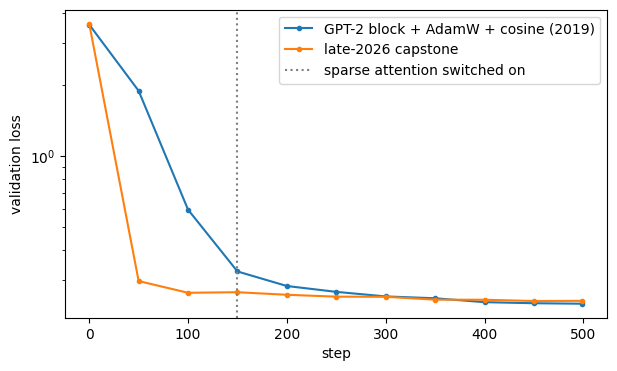

In [5]:
def newton_schulz(G, steps=5):
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G / (G.norm() + 1e-7); tr = X.shape[0] > X.shape[1]
    if tr: X = X.T
    for _ in range(steps): A = X @ X.T; X = a * X + (b * A + c * A @ A) @ X
    return X.T if tr else X

class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95): super().__init__(params, dict(lr=lr, momentum=momentum))
    @torch.no_grad()
    def step(self):
        for g in self.param_groups:
            for p in g["params"]:
                if p.grad is None: continue
                buf = self.state[p].setdefault("buf", torch.zeros_like(p)); buf.mul_(g["momentum"]).add_(p.grad)
                G = p.grad + g["momentum"] * buf
                upd = torch.stack([newton_schulz(x) for x in G]) if G.ndim == 3 else newton_schulz(G)
                p.add_(upd, alpha=-g["lr"] * max(1, p.shape[-2] / p.shape[-1]) ** 0.5)

def get_batch(src, B=32):
    ix = torch.randint(0, len(src) - CTX - 2, (B,), device=device)
    return torch.stack([src[i:i + CTX + 1] for i in ix])

@torch.no_grad()
def val_loss(m):
    m.eval(); g = torch.Generator().manual_seed(7); out = []
    for _ in range(8):
        ix = torch.randint(0, len(val_data) - CTX - 1, (32,), generator=g).to(device)
        s = torch.stack([val_data[i:i + CTX + 1] for i in ix])
        out.append(F.cross_entropy(m(s[:, :-1]).reshape(-1, V), s[:, 1:].reshape(-1)).item())
    m.train(); return float(np.mean(out))

def pretrain(m, steps=500, late=True, warm=150):
    if late:
        hidden = [p for n, p in m.named_parameters() if p.ndim >= 2 and not n.startswith(("tok", "head")) and "router" not in n and ".iq" not in n and ".ik" not in n]
        hid = {id(p) for p in hidden}
        rest = [p for p in m.parameters() if id(p) not in hid]
        opts = [Muon(hidden, lr=0.02), torch.optim.AdamW(rest, lr=3e-3, betas=(0.9, 0.95), weight_decay=0.0)]
    else:
        opts = [torch.optim.AdamW(m.parameters(), lr=3e-3, betas=(0.9, 0.95), weight_decay=0.1)]
    base = [[g["lr"] for g in o.param_groups] for o in opts]
    ema = [p.detach().clone() for p in m.parameters()]; curve = []
    for s in range(steps):
        f = min(1, (s + 1) / 30) * (1.0 if late else 0.5 * (1 + math.cos(math.pi * s / steps)))   # constant (late) vs cosine (2019)
        for o, lrs in zip(opts, base):
            for g, lr in zip(o.param_groups, lrs): g["lr"] = lr * f
        if late and s == warm:
            for a in m.attns(): a.sparse = True
        seq = get_batch(train_data); x, y = seq[:, :-1], seq[:, 1:]
        if late:
            main, mtp = m(x, with_mtp=True)
            loss = F.cross_entropy(main.reshape(-1, V), y.reshape(-1)) + 0.3 * F.cross_entropy(mtp.reshape(-1, V), seq[:, 2:].reshape(-1)) + sum(a.kl for a in m.attns())
        else:
            loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1))
        for o in opts: o.zero_grad()
        loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        for o in opts: o.step()
        if late:
            for moe in m.moes(): moe.update_bias()
            with torch.no_grad():
                for e, p in zip(ema, m.parameters()): e.lerp_(p, 0.02)
        if s % 50 == 0 or s == steps - 1: curve.append((s, val_loss(m)))
    if late:                                                                              # hand over the averaged weights
        raw = val_loss(m)
        with torch.no_grad():
            for e, p in zip(ema, m.parameters()): p.copy_(e)
        print(f"   constant LR: raw weights {raw:.4f} -> EMA-averaged weights {val_loss(m):.4f}")
    return curve

runs = {}
for name, make, late in [("GPT-2 block + AdamW + cosine (2019)", GPT2, False), ("late-2026 capstone", Late2026LM, True)]:
    seed_everything(0); m = make().to(device); t0 = time.time()
    curve = pretrain(m, late=late); runs[name] = (m, curve)
    print(f"{name:36s} final val loss {val_loss(m):.4f} | {time.time() - t0:.0f}s")
plt.figure(figsize=(7, 4))
for name, (_, c) in runs.items(): plt.plot(*zip(*c), marker=".", label=name)
plt.axvline(150, c="gray", ls=":", label="sparse attention switched on"); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("validation loss"); plt.legend(); plt.show()

## Inspect the trained model

In [6]:
m = runs["late-2026 capstone"][0]
x = get_batch(val_data)[:, :-1]
with torch.no_grad(): m(x)
for i, moe in enumerate(m.moes()):
    share = (moe.load / moe.load.sum()).cpu().numpy()
    print(f"LatentMoE {i}: busiest expert {share.max():.3f}, idlest {share.min():.3f} (uniform {1 / moe.E:.3f})")
with torch.no_grad():
    for a in m.attns(): a.sparse = False
    dense_loss = val_loss(m)
    for a in m.attns(): a.sparse = True
print(f"validation loss with sparse global layers {val_loss(m):.4f} vs. the same weights run densely {dense_loss:.4f}")
d, L_lin, L_glob, T_long = 96, 6, 2, 1_000_000
state = L_lin * 2 * (d // 2) * (d // 2)
print(f"memory at 1M tokens: GDN-2 states {state:,} floats (fixed) + global KV {L_glob * 2 * 2 * (d // 4) * T_long:,} floats (GQA, 2 KV heads) "
      f"vs. an all-attention 8-layer model {8 * 2 * d * T_long:,}")

LatentMoE 0: busiest expert 0.046, idlest 0.022 (uniform 0.031)
LatentMoE 1: busiest expert 0.069, idlest 0.008 (uniform 0.031)
LatentMoE 2: busiest expert 0.091, idlest 0.006 (uniform 0.031)
LatentMoE 3: busiest expert 0.116, idlest 0.000 (uniform 0.031)
LatentMoE 4: busiest expert 0.084, idlest 0.002 (uniform 0.031)
LatentMoE 5: busiest expert 0.056, idlest 0.010 (uniform 0.031)
LatentMoE 6: busiest expert 0.055, idlest 0.013 (uniform 0.031)
LatentMoE 7: busiest expert 0.049, idlest 0.015 (uniform 0.031)
validation loss with sparse global layers 0.2364 vs. the same weights run densely 0.2365
memory at 1M tokens: GDN-2 states 27,648 floats (fixed) + global KV 192,000,000 floats (GQA, 2 KV heads) vs. an all-attention 8-layer model 1,536,000,000


## Generate

In [7]:
@torch.no_grad()
def generate(m, prompt, n=160, temperature=0.7):
    m.eval(); idx = torch.tensor([encode(prompt)], device=device)
    for _ in range(n):
        p = F.softmax(m(idx[:, -CTX:])[:, -1] / temperature, -1); idx = torch.cat([idx, torch.multinomial(p, 1)], 1)
    return decode(idx[0].tolist())
print(generate(m, "The router learns"))

The router learns every expert quickly because each layer copies the key and value. A small network compresses the key and value carefully because a small network routes a hidde


## Where this leaves us (November 2026)
- The late-2026 open frontier converged on: **mostly linear-memory layers** (GDN-2/KDA, Mamba-2/3) with a **few sparse global layers** whose indexers are themselves made cheap; **residual paths that learn to mix depth** (AttnRes, Gated Residual, mHC); **MoE made fine-grained without extra communication** (LatentMoE); MTP; Muon; and simpler schedules.
- In parallel, two structural bets: **split the stack** so that prompt tokens skip half the layers (DeepSeek-V4.1's causal encoder–decoder, notebook 66), and **loop the stack** for more compute per parameter (looped transformers, notebook 67).
- On this toy corpus, the capstone and the GPT-2 baseline reach similar losses; the late-2026 recipe is built for 1M-token contexts and trillion-parameter MoEs, where its memory and compute savings dominate. What the toy shows is that all the pieces fit together and train stably: switching to sparse attention mid-run, expert balancing, the averaged weights.
- Every piece is still the weighted sum + nonlinearity of 1943 (notebook 01), trained by backpropagation (notebook 08).